# Working with the Nordic Gridded Climate Dataset

**Last updated:** 2026-10-24

[![binder](https://mybinder.org/badge.svg)](https://mybinder.org/v2/gh/metno/c3s-training-submodule-insitu-obs/main?labpath=nordic_gridded_climate_dataset.ipynb)
[![kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/metno/c3s-training-submodule-insitu-obs/blob/main/nordic_gridded_climate_dataset.ipynb)
[![colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/metno/c3s-training-submodule-insitu-obs/blob/main/nordic_gridded_climate_dataset.ipynb)

:::{note}
This notebook can be run on free online platforms, such as Binder, Kaggle and Colab, or they can be accessed from GitHub. The links to run this notebook in these environments are provided here, but please note they are not supported by ECMWF.
:::

## I The Nordic Gridded Climate Dataset in brief

The Nordic Gridded Climate Dataset (NGCD) is a high-resolution, observational gridded dataset of daily mean, minimum and maximum temperatures, as well as daily total precipitation, covering Finland, Sweden and Norway. The dataset begins on 1 January 1961 and is updated twice a year. See [the dataset overview](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=overview) for more details.

Two spatial interpolation methods are applied to the same station observations, and both are available for every variable:

- **Type 1 (`kriging`)**: a deterministic interpolation approach.
- **Type 2 (`stochastic Bayesian`)**: a stochastic interpolation approach.

This notebook uses both types. The `spatial_interpolation_method` keyword of the request selects the method.


## II Learning objectives 🎯
### What to expect from this Jupyter notebook

This Jupyter notebook introduces the Nordic Gridded Climate Dataset. NGCD data can be downloaded from the Climate Data Store using the graphical interface or an API request. The notebook demonstrates how to request and read the data, create maps and calculate statistics.


### Target audience

- **Skill level:** Beginner to intermediate
- **Role or use case:** Researchers, students, educators, and other users of gridded climate observations
- **Domain background assumed:** Basic familiarity with Python and introductory data analysis

## III Prepare your environment


### III-1 How to access and run the notebook

This tutorial is provided as a Jupyter Notebook and can be executed either in a cloud-based environment or on a local machine. Three simple ways to run it locally are described below.

#### Option 1: VS Code

1. Install the [Python](https://marketplace.visualstudio.com/items?itemName=ms-python.python) and [Jupyter](https://marketplace.visualstudio.com/items?itemName=ms-toolsai.jupyter) extensions.
2. Open this repository folder in VS Code, then open this notebook.
3. Click **Select Kernel** in the upper-right corner, then select **Python Environments...** and **Create Python Environment**.
4. Choose **Venv** to create a `.venv` virtual environment in the current workspace. If a `.venv` already exists, select it rather than creating another one.
5. If prompted to choose an interpreter, select Python **3.12**, for example.
6. When asked which dependencies to install, select **requirements.txt** and confirm.
7. Select the `.venv` environment as the notebook kernel if it is not already selected, then run the cells in order. If VS Code prompts you to install **ipykernel**, accept the installation.

#### Option 2: Jupyter Lab with uv

1. Install [uv](https://docs.astral.sh/uv/getting-started/installation/) if you don't already have it.
2. From a terminal in this repository, run:
   ```bash
   uv sync
   uv run jupyter lab
   ```
3. Jupyter Lab opens in your browser. Open this notebook, select the project's kernel, and run the cells.

#### Option 3: pip and requirements.txt

1. Create and activate a virtual environment:
   ```bash
   python -m venv .venv
   source .venv/bin/activate  # on Windows: .venv\Scripts\activate
   ```
2. Install the dependencies listed in `requirements.txt`, plus Jupyter Lab:
   ```bash
   pip install -r requirements.txt jupyterlab ipykernel
   ```
3. Launch Jupyter Lab and open the notebook:
   ```bash
   jupyter lab
   ```

### III-2 Import libraries and define some variables

Reading the downloaded NetCDF files requires the **netCDF4** backend in addition to xarray. It is listed in both `requirements.txt` and `pyproject.toml`. If your environment was created before this dependency was added, run `uv sync` (for the uv environment) or `python -m pip install -r requirements.txt` in a terminal with your notebook's environment activated. Then restart the notebook kernel and rerun the import cell. Make sure the selected kernel uses the environment where you installed the dependencies.


In [8]:
# Import libraries
import os
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
from zipfile import ZipFile

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cdsapi
import matplotlib.pyplot as plt
import netCDF4  # noqa: F401 -- Required backend for xarray's NetCDF reader.
import numpy as np
import xarray as xr
from matplotlib.colors import BoundaryNorm, ListedColormap

# Variables used further in the notebook
dataset = "insitu-gridded-observations-nordic"
version = "26_03"
interpolation_type_mapping = {"kriging": "type_1", "stochastic Bayesian": "type_2"}
variables_mapping = {
    "precipitation": "RR",
    "mean_temperature": "TG",
    "maximum_temperature": "TX",
    "minimum_temperature": "TN",
}
projection = ccrs.LambertConformal(
    central_longitude=15,
    central_latitude=63,
    standard_parallels=(63, 63),
    globe=ccrs.Globe(ellipse=None, semimajor_axis=6371000, semiminor_axis=6371000),
)

### III-3 Set up credentials
Set up your `~/.cdsapirc` file with the credentials described on the [CDS API instructions page](https://cds.climate.copernicus.eu/how-to-api). You must be logged in to view your credentials. The file should contain entries in this format:
```
url: https://cds.climate.copernicus.eu/api
key: <PERSONAL-ACCESS-TOKEN>
```

:::{important}
Before your first request, accept the dataset licence at the bottom of the [download page](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=download) while logged in. Without this, API requests fail with an error.
:::


## IV Analyse some data

The three analysis sections (IV-1, IV-2 and IV-3) can be run independently after the import and setup cells. Within each section, run cells of the a, b and c subsections in order because later cells use variables defined in earlier cells.

a. This cell demonstrates how to download data files with an API request. The files are stored in a ZIP archive; you can change its name by editing `zip_archive_name`. You can also generate an API request snippet on the [dataset download page](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=download) or use that page to download the files manually.

b. Run cell of the previous subsection first (a) and make sure the ZIP archive has finished downloading. It should contain the NetCDF files matching the requested variables and dates. In this cell, we read the files, load the data into memory and inspect the variables and metadata.

c. Run cell of the previous subsection first (b). Cell c plots the data as maps or time series. The maps use a Lambert conformal conic display projection (`+proj=lcc +lat_0=63 +lon_0=15 +lat_1=63 +lat_2=63 +no_defs +R=6.371e+06`). Cartopy downloads coastline and border data the first time they are requested.


### IV-1 Maps for the temperature variables
#### IV-1-a Define your data request for the temperature variables
For a quick example, we download three files for 1 January 1961, containing daily mean, minimum and maximum temperatures. We use the kriging interpolation method (type 1).

In [4]:
year = "1961"
month = "01"
day = "01"
variables = [
    "mean_temperature",
    "minimum_temperature",
    "maximum_temperature",
]
interpolation = "kriging"
interpolation_type = interpolation_type_mapping[interpolation]
request = {
    "variable": variables,
    "spatial_interpolation_method": [interpolation_type],
    "year": [year],
    "month": [month],
    "day": [day],
    "version": [version],
}

zip_archive_name = f"ngcd_T_{interpolation_type}_{year}{month}{day}_ver{version}.zip"
# Reuse the archive if it has already been downloaded.
if not os.path.exists(zip_archive_name):
    client = cdsapi.Client()
    client.retrieve(dataset, request).download(zip_archive_name)

#### IV-1-b Read the downloaded temperature data

In [9]:
# Dictionary for storing variable data
variable_data = {}
date_str = f"{year}{month}{day}"
# Extract the ZIP archive to a temporary directory that is cleaned up after use.
with ZipFile(zip_archive_name) as archive, TemporaryDirectory() as data_dir:
    for index_variable, variable in enumerate(variables):
        variable_name = variables_mapping[variable]
        ncfile = (
            f"NGCD_{variable_name}_{interpolation_type.replace('_', '')}"
            f"_version_{version.replace('_', '.')}_{date_str}.nc"
        )
        if ncfile not in archive.namelist():
            raise FileNotFoundError(f"{ncfile} is not in {zip_archive_name}.")

        # Choose NetCDF4 explicitly instead of relying on xarray's backend auto-detection.
        with xr.open_dataset(
            archive.extract(ncfile, data_dir), engine="netcdf4"
        ) as data:
            print(f"Data variables in file {ncfile}:")
            for name, data_variable in data.data_vars.items():
                if data_variable.attrs.get("long_name", ""):
                    print(
                        f"  {name}: {data_variable.attrs.get('long_name', '')} "
                        f" units: {data_variable.attrs.get('units', '')} "
                        f"(dimensions: {data_variable.dims})"
                    )
            # Load the data into memory before the file is closed.
            field = data[variable_name]
            if field.sizes["time"] != 1:  # some format check
                raise ValueError(
                    f"{ncfile}: expected exactly one time step, found {field.sizes['time']}."
                )
            variable_data[variable_name] = (
                field.isel(time=0, drop=True).transpose("Y", "X").load()
            )

            if index_variable == 0:
                # the mapping is the same for all variables
                mapping = data[field.attrs["grid_mapping"]]
                source_crs = ccrs.Projection(mapping.attrs["proj4"])
                # show the coordinates and an example of metadata
                print(f"Some content of {ncfile}")
                print("Coordinates/time variables:")
                for name, coordinate in data.coords.items():
                    print(f"  {name} (coordinate): {coordinate.dims}")
                print("Example of dataset attributes:")
                for attribute in ["references", "source", "project"]:
                    print(f"  {attribute}: {data.attrs[attribute]}")
                print(f"  Grid mapping: {mapping.attrs['grid_mapping_name']}")
                print(
                    f"  Grid size: {data.sizes['X']} x-points, {data.sizes['Y']} y-points"
                )
                print(
                    f"  Latitude min-max: {np.nanmin(data['lat'].values):.2f}, {np.nanmax(data['lat'].values):.2f}"
                )
                print(
                    f"  Longitude min-max: {np.nanmin(data['lon'].values):.2f}, {np.nanmax(data['lon'].values):.2f}"
                )

Data variables in file NGCD_TG_type1_version_26.03_19610101.nc:
  TG: daily mean temperature  units: K (dimensions: ('time', 'Y', 'X'))
Some content of NGCD_TG_type1_version_26.03_19610101.nc
Coordinates/time variables:
  Y (coordinate): ('Y',)
  X (coordinate): ('X',)
  time (coordinate): ('time',)
  lat (coordinate): ('Y', 'X')
  lon (coordinate): ('Y', 'X')
Example of dataset attributes:
  references: Tveito, O.E., E.J.Førland, R.Heino, I.Hanssen-Bauer, H.Alexandersson, B.Dahlström, A.Drebs, C.Kern-Hansen, T.Jónsson, E.Vaarby-Laursen and Y.Westman. (2000), Nordic Temperature Maps, DNMI Klima 9/00 KLIMA, Norwegian Meteorological Institute
  source: MET Norway
  project: C3S2 311a Lot3
  Grid mapping: lambert_azimuthal_equal_area
  Grid size: 1550 x-points, 2020 y-points
  Latitude min-max: 52.40, 72.02
  Longitude min-max: 0.91, 42.22
Data variables in file NGCD_TN_type1_version_26.03_19610101.nc:
  TN: daily minimum temperature  units: K (dimensions: ('time', 'Y', 'X'))
Data variabl

#### IV-1-c Plot daily temperature maps
The maps show daily mean, minimum and maximum temperatures for 1 January 1961.

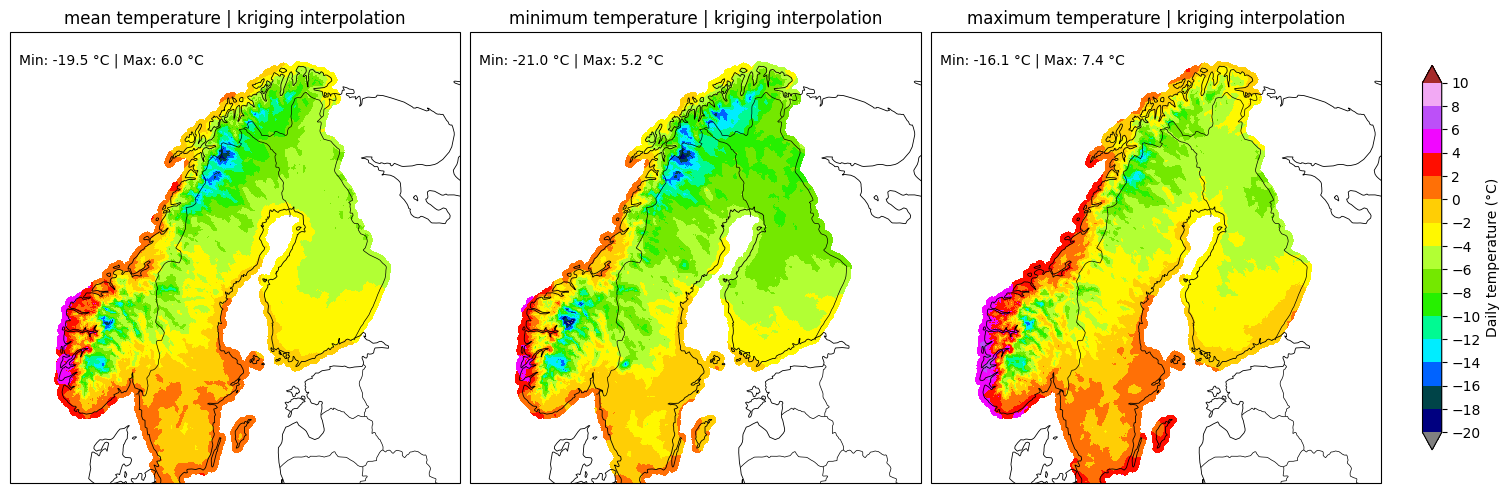

In [10]:
levels = np.arange(-20, 12, 2)
n_bins = len(levels) - 1  # (N-1) bins between the N boundaries
# Use a discrete colour scale to make differences easier to see.
base = plt.get_cmap(
    "gist_ncar", n_bins + 1
)  # +1 so one excludes the white color from gist_ncar colorscale
cmap = ListedColormap(base(range(n_bins)))
cmap.set_over("brown")
cmap.set_under("grey")
cmap.set_bad("white")
norm = BoundaryNorm(levels, cmap.N)

fig, axes = plt.subplots(
    1,
    len(variables),
    figsize=(5 * len(variables), 6),
    subplot_kw={"projection": projection},
    squeeze=False,
    layout="constrained",
)
axes = axes.ravel()
for ax, variable in zip(axes, variables):
    variable_name = variables_mapping[variable]
    # Convert temperature from kelvin to degrees Celsius.
    temperature = variable_data[variable_name] - 273.15
    min_temperature = float(temperature.min())
    max_temperature = float(temperature.max())
    mesh = ax.pcolormesh(
        temperature.X,
        temperature.Y,
        temperature,
        transform=source_crs,
        cmap=cmap,
        norm=norm,
        shading="nearest",
        rasterized=True,
    )
    ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
    ax.set_title(f"{variable.replace('_', ' ')} | {interpolation} interpolation")
    ax.text(
        0.02,
        0.92,
        f"Min: {min_temperature:.1f} °C | Max: {max_temperature:.1f} °C",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="bottom",
        horizontalalignment="left",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
    )

colorbar = fig.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    boundaries=levels,
    ticks=levels,
    spacing="uniform",
    extend="both",
    shrink=0.65,
    pad=0.03,
)
colorbar.set_label("Daily temperature (°C)")
fig.savefig(
    f"temperature_{interpolation_type}_{date_str}_ver{version}.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()

### IV-2 Precipitation maps for Hans storm
#### IV-2-a Define your data request for precipitation
This section demonstrates how to examine precipitation during an event. For a quick example, we download daily precipitation files for 7–9 August 2023 using the stochastic Bayesian interpolation method (type 2). These dates cover [Storm Hans](https://www.met.no/en/archive/the-extreme-weather-hans-is-bringing-an-extremely-large-amount-of-rain-over-southern-norway).

In [11]:
interpolation = "stochastic Bayesian"
interpolation_type = interpolation_type_mapping[interpolation]

year = "2023"
month = "08"
days = ["07", "08", "09"]
request = {
    "variable": ["precipitation"],
    "spatial_interpolation_method": [interpolation_type],
    "year": [year],
    "month": [month],
    "day": days,
    "version": [version],
}

zip_archive_name = f"ngcd_RR_{interpolation_type}_{year}{month}{days[0]}_{year}{month}{days[-1]}_ver{version}.zip"

# Reuse the archive if it has already been downloaded.
if not os.path.exists(zip_archive_name):
    client = cdsapi.Client()
    client.retrieve(dataset, request).download(zip_archive_name)

#### IV-2-b Read the downloaded precipitation data

In [12]:
# List that will contain the precipitation data per date
precipitation_data = []
dates = [f"{year}{month}{day}" for day in days]
if not dates:
    raise ValueError("Choose at least one day in the request cell.")
with ZipFile(zip_archive_name) as archive, TemporaryDirectory() as data_dir:
    for index, date_str in enumerate(dates):
        ncfile = f"NGCD_RR_{interpolation_type.replace('_', '')}_version_{version.replace('_', '.')}_{date_str}.nc"
        if ncfile not in archive.namelist():
            raise FileNotFoundError(
                f"{ncfile} is not in {zip_archive_name}. Check the requested dates, version and interpolation type."
            )
        # Choose NetCDF4 explicitly instead of relying on xarray's backend auto-detection.
        with xr.open_dataset(
            archive.extract(ncfile, data_dir), engine="netcdf4"
        ) as data:
            # The listing identifies RR as daily precipitation; data.RR accesses that variable.
            # It is expected to have only one time value in each file
            if data.RR.sizes["time"] != 1:
                raise ValueError(
                    f"{ncfile}: expected exactly one time step, found {data.RR.sizes['time']}."
                )
            # Load it into memory before the file closes and the temporary directory is removed.
            precipitation_data.append(
                data.RR.isel(time=0, drop=True).transpose("Y", "X").load()
            )
            # Read the grid mapping once; it is the same for all files in the archive.
            if index == 0:
                mapping = data[data.RR.attrs["grid_mapping"]]
                source_crs = ccrs.Projection(mapping.attrs["proj4"])

#### IV-2-c Plot of precipitation maps
For precipitation, 1 kg/m² is equivalent to 1 mm of water.
##### Plots daily maps
The maps show daily precipitation in the order of `days` (by default, 7th to 9th August 2023). All maps use the same stepped colour scale in millimetres; purple indicates totals above 50 mm.

Source: [Nordic Gridded Climate Dataset (NGCD), Climate Data Store](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=overview).

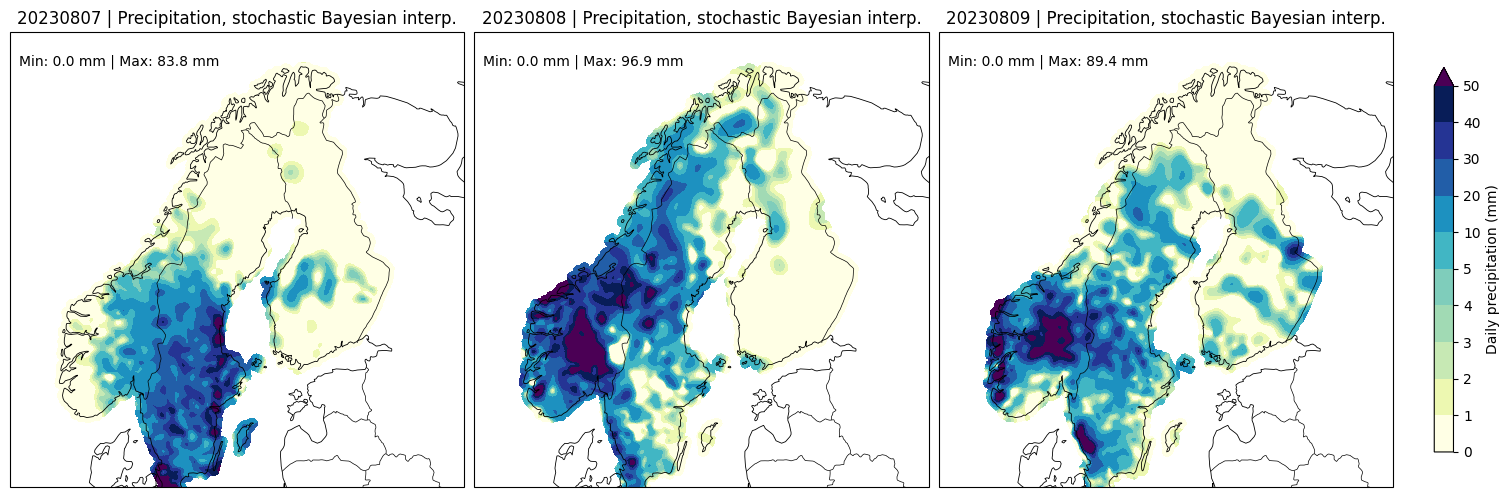

In [13]:
levels = [0, 1, 2, 3, 4, 5, 10, 20, 30, 40, 50]

cmap = ListedColormap(
    [
        "#ffffe5",
        "#edf8b1",
        "#c7e9b4",
        "#a1dab4",
        "#7fcdbb",
        "#41b6c4",
        "#1d91c0",
        "#225ea8",
        "#253494",
        "#081d58",
    ]
)
cmap.set_over("#4b0055")
cmap.set_bad("white")
norm = BoundaryNorm(levels, cmap.N)

fig, axes = plt.subplots(
    1,
    len(dates),
    figsize=(5 * len(dates), 6),
    subplot_kw={"projection": projection},
    squeeze=False,
    layout="constrained",
)
axes = axes.ravel()
for ax, date, rain in zip(axes, dates, precipitation_data):
    min_precipitation = float(rain.min())
    max_precipitation = float(rain.max())
    mesh = ax.pcolormesh(
        rain.X,
        rain.Y,
        rain,
        transform=source_crs,
        cmap=cmap,
        norm=norm,
        shading="auto",
        rasterized=True,
    )
    ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
    ax.coastlines(resolution="50m", linewidth=0.6)
    ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
    ax.set_title(f"{date} | Precipitation, {interpolation} interp.")
    ax.text(
        0.02,
        0.92,
        f"Min: {min_precipitation:.1f} mm | Max: {max_precipitation:.1f} mm",
        transform=ax.transAxes,
        fontsize=10,
        verticalalignment="bottom",
        horizontalalignment="left",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
    )

colorbar = fig.colorbar(
    mesh,
    ax=axes,
    orientation="vertical",
    boundaries=levels,
    ticks=levels,
    spacing="uniform",
    extend="max",
    shrink=0.65,
    pad=0.03,
)
colorbar.set_label("Daily precipitation (mm)")
fig.savefig(
    f"precipitation_{interpolation_type}_{dates[0]}_{dates[-1]}_ver{version}.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()

##### Plot 3-day accumulated precipitation map
We now compute the accumulated precipitation for the 3 days of the Hans storm, and plot a map of the total precipitation for the event.

Source: [Nordic Gridded Climate Dataset (NGCD), Climate Data Store](https://cds.climate.copernicus.eu/datasets/insitu-gridded-observations-nordic?tab=overview).

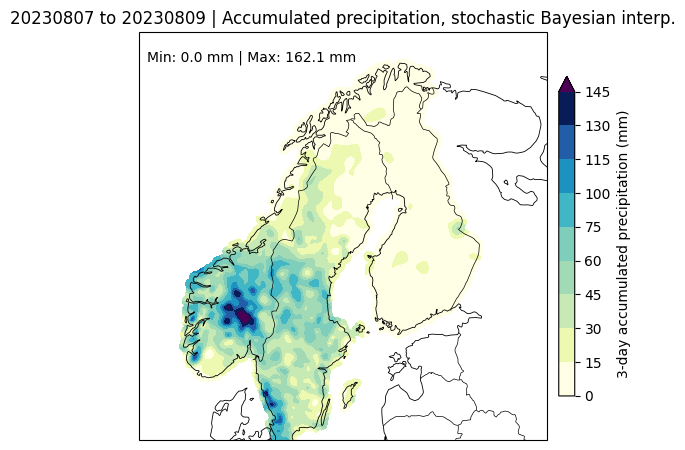

In [ ]:
levels = [0, 15, 30, 45, 60, 75, 100, 115, 130, 145]
norm = BoundaryNorm(levels, cmap.N)

# Sum the daily maps into a single 3-day accumulated total.
accumulated_precipitation = sum(precipitation_data)
min_precipitation = float(accumulated_precipitation.min())
max_precipitation = float(accumulated_precipitation.max())

fig, ax = plt.subplots(
    figsize=(5, 5), subplot_kw={"projection": projection}, layout="constrained"
)
mesh = ax.pcolormesh(
    accumulated_precipitation.X,
    accumulated_precipitation.Y,
    accumulated_precipitation,
    transform=source_crs,
    cmap=cmap,
    norm=norm,
    shading="auto",
    rasterized=True,
)
ax.set_extent([3, 33, 55, 72], crs=ccrs.PlateCarree())
ax.coastlines(resolution="50m", linewidth=0.6)
ax.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5)
ax.set_title(
    f"{dates[0]} to {dates[-1]} | Accumulated precipitation, {interpolation} interp."
)

ax.text(
    0.02,
    0.92,
    f"Min: {min_precipitation:.1f} mm | Max: {max_precipitation:.1f} mm",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="bottom",
    horizontalalignment="left",
    bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 4},
)

colorbar = fig.colorbar(
    mesh,
    ax=ax,
    orientation="vertical",
    boundaries=levels,
    ticks=levels,
    spacing="uniform",
    extend="max",
    shrink=0.65,
    pad=0.03,
)
colorbar.set_label("3-day accumulated precipitation (mm)")
fig.savefig(
    f"precipitation_accumulated_{interpolation_type}_{dates[0]}_{dates[-1]}_ver{version}.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()

#### IV-2-d  📖 Exercise: Try kriging interpolation

Repeat the precipitation maps for the same dates using **kriging (type 1)** instead of stochastic Bayesian interpolation (type 2).

1. Set `interpolation = "kriging"` in the data-loading cell.
2. Rerun the data-loading cell, then the plotting cell, keeping the same map extent and colour scale.
3. Compare the maps from the two interpolation methods: where do the precipitation patterns differ?

### IV-3 Temperature time-series plots
#### IV-3-a Download data for a month

In [ ]:
interpolation = "stochastic Bayesian"
interpolation_type = interpolation_type_mapping[interpolation]
year = "2024"
month = "01"
days = [
    "01",
    "02",
    "03",
    "04",
    "05",
    "06",
    "07",
    "08",
    "09",
    "10",
    "11",
    "12",
    "13",
    "14",
    "15",
    "16",
    "17",
    "18",
    "19",
    "20",
    "21",
    "22",
    "23",
    "24",
    "25",
    "26",
    "27",
    "28",
    "29",
    "30",
    "31",
]
request = {
    "variable": ["mean_temperature"],
    "spatial_interpolation_method": [interpolation_type],
    "year": [year],
    "month": [month],
    "day": days,
    "version": [version],
}
zip_archive_name = f"ngcd_TG_{interpolation_type}_{year}{month}{days[0]}_{year}{month}{days[-1]}_ver{version}.zip"

# Reuse the archive if it has already been downloaded.
if not os.path.exists(zip_archive_name):
    client = cdsapi.Client()
    client.retrieve(dataset, request).download(zip_archive_name)

#### IV-3-b Read the downloaded temperature data (month)

In [ ]:
temperature_data = []
dates = [f"{year}{month}{day}" for day in days]
if not dates:
    raise ValueError("Choose at least one day in the request cell.")
with ZipFile(zip_archive_name) as archive, TemporaryDirectory() as data_dir:
    for index, date_str in enumerate(dates):
        ncfile = f"NGCD_TG_{interpolation_type.replace('_', '')}_version_{version.replace('_', '.')}_{date_str}.nc"
        if ncfile not in archive.namelist():
            raise FileNotFoundError(
                f"{ncfile} is not in {zip_archive_name}. Check the requested dates, version and interpolation type."
            )
        # Choose NetCDF4 explicitly instead of relying on xarray's backend auto-detection.
        with xr.open_dataset(
            archive.extract(ncfile, data_dir), engine="netcdf4"
        ) as data:
            # data.TG accesses the mean temperature
            # Use the filename date: type-1 time units can be incorrect.
            if data.TG.sizes["time"] != 1:
                raise ValueError(
                    f"{ncfile}: expected exactly one time step, found {data.TG.sizes['time']}."
                )
            # Load it into memory before the file closes and the temporary directory is removed.
            temperature_data.append(
                data.TG.isel(time=0, drop=True).transpose("Y", "X").load()
            )
            # Read the grid mapping once; it is the same for all files in the archive.
            if index == 0:
                mapping = data[data.TG.attrs["grid_mapping"]]
                source_crs = ccrs.Projection(mapping.attrs["proj4"])

#### IV-3-c Plot time series of the mean temperature

The daily spatial mean is the unweighted mean of valid grid-cell temperatures. Because NGCD uses a regular equal-area grid, each valid grid cell represents approximately the same area.

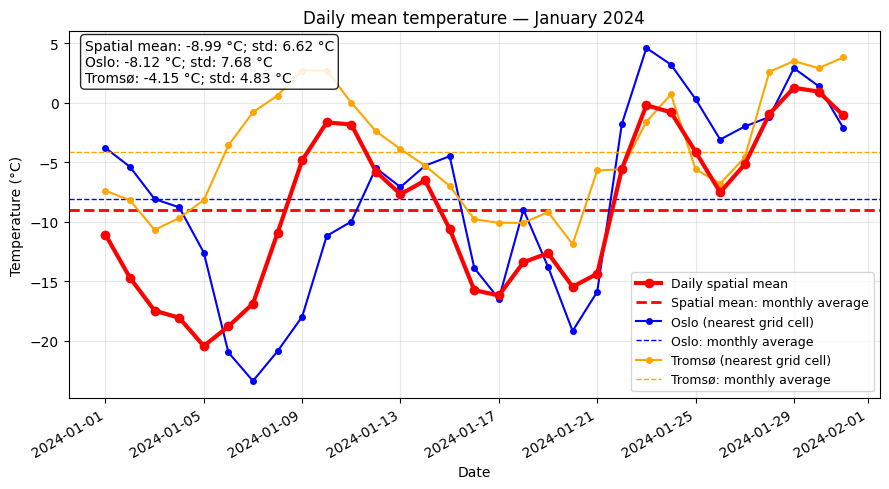

In [ ]:
time_index = [
    datetime.strptime(date, "%Y%m%d").replace(tzinfo=timezone.utc) for date in dates
]

cities = {"Oslo": (10.7167, 59.95, "blue"), "Tromsø": (18.9553, 69.6492, "orange")}

# Grid coordinates for each city, computed once (the grid is the same for all NGCD files).
reference = temperature_data[0]
city_xy = {}
for city, (longitude, latitude, _) in cities.items():
    x, y = source_crs.transform_point(longitude, latitude, src_crs=ccrs.PlateCarree())
    if not (
        reference.X.min().item() <= x <= reference.X.max().item()
        and reference.Y.min().item() <= y <= reference.Y.max().item()
    ):
        raise ValueError(f"{city} is outside the loaded grid.")
    city_xy[city] = (x, y)

domain_values = []
city_values = {city: [] for city in cities}

for data in temperature_data:
    temperature = data - 273.15
    domain_values.append(temperature.mean(dim=("Y", "X"), skipna=True))

    for city, (x, y) in city_xy.items():
        city_values[city].append(temperature.sel(X=x, Y=y, method="nearest"))

daily_mean = xr.concat(domain_values, dim="time").assign_coords(time=time_index)
if not daily_mean.notnull().any().item():
    raise ValueError("The domain-average series has no valid temperatures.")

monthly_avg = daily_mean.mean("time", skipna=True).item()
# Population standard deviation (ddof=0 for dividing by the N values) of the daily means over the month, ignoring NaNs
monthly_std = daily_mean.std("time", skipna=True, ddof=0).item()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    time_index,
    daily_mean.values,
    marker="o",
    color="red",
    linewidth=3,
    zorder=5,
    label="Daily spatial mean",
)
ax.axhline(
    monthly_avg,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Spatial mean: monthly average",
)

stats_text = [f"Spatial mean: {monthly_avg:.1f} °C; std: {monthly_std:.1f} °C"]

for city, (_, _, color) in cities.items():
    city_series = xr.concat(city_values[city], dim="time").assign_coords(
        time=time_index
    )
    if not city_series.notnull().any().item():
        raise ValueError(f"The grid cell nearest {city} has no valid temperatures.")

    city_avg = city_series.mean("time", skipna=True).item()
    city_std = city_series.std("time", skipna=True, ddof=0).item()
    stats_text.append(f"{city}: {city_avg:.1f} °C; std: {city_std:.1f} °C")

    ax.plot(
        time_index,
        city_series.values,
        marker="o",
        markersize=4,
        color=color,
        linewidth=1.5,
        label=f"{city} (nearest grid cell)",
    )
    ax.axhline(
        city_avg,
        color=color,
        linestyle="--",
        linewidth=1,
        label=f"{city}: monthly average",
    )

ax.text(
    0.02,
    0.98,
    "\n".join(stats_text),
    transform=ax.transAxes,
    va="top",
    fontsize=10,
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.85},
)

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title(f"Daily mean temperature — {time_index[0]:%B %Y}")
ax.grid(alpha=0.3)
ax.legend(loc="lower right", fontsize=9)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(
    f"monthly_mean_temperature_{interpolation_type}_{dates[0]}_{dates[-1]}_ver{version}.png",
    dpi=140,
    bbox_inches="tight",
)
plt.show()

#### IV-3-d 📖 Exercises
1. Add Bergen to the plot by adding `"Bergen": (5.3221, 60.3930, "green")` to the `cities` dictionary.
2. Plot January for a different year by repeating the steps in this section.
3. Check the API request to download data from January to February 2020. Note that the CDS client handles well the days that do not exist in February.

## V Take home messages 📌




- NGCD can be used to study daily mean, minimum and maximum temperatures and daily precipitation across the Nordic countries. The dataset begins in 1961 and is updated twice a year.
- NGCD data can be downloaded manually from the Climate Data Store or by using an API request. This notebook demonstrates both approaches.
- The data can be explored with maps, accumulated precipitation maps and time-series plots.

## VI References

### Type 1 data

Tveito, O.E., I. Bjørdal, A.O. Skjelvåg, B. Aune. (2005) A GIS-based agro-ecological decision system based on gridded climatology, Meteorol. Appl., 12, 57–68, https://rmets.onlinelibrary.wiley.com/doi/10.1017/S1350482705001490

Tveito, O.E., E.J. Førland, R. Heino, I. Hanssen-Bauer, H. Alexandersson, B. Dahlström, A. Drebs, C. Kern-Hansen, T. Jónsson, E. Vaarby-Laursen and Y. Westman. (2000), [Nordic Temperature Maps, DNMI Klima 9/00 KLIMA](https://www.met.no/publikasjoner/met-report/met-report-2000/_/attachment/download/fd5c813f-c990-4701-b32d-1cd5739366b4:3c546bbb335949d58fdeb1e043bb335a9ee3a6fa/MET-report-09-2000.pdf), Norwegian Meteorological Institute

### Type 2 data

Lussana, C., O.E. Tveito, and F. Uboldi. (2018), Three-dimensional spatial interpolation of 2m temperature over Norway. Q.J.R. Meteorol. Soc. https://rmets.onlinelibrary.wiley.com/doi/10.1002/qj.3208

Lussana, C., T. Saloranta, T. Skaugen, J. Magnusson, O.E. Tveito, and J. Andersen (2018), seNorge2 daily precipitation, an observational gridded dataset over Norway from 1957 to the present day, Earth Syst. Sci. Data, 10, 235-249, https://doi.org/10.5194/essd-10-235-2018.